# Two models and their average for the DrEval chocolate challenge

**Task.** Predict how strongly a drug inhibits a cancer cell line (ln IC50) for cell lines the model has never seen. This is the leave-cell-line-out (LCO) setting of [DrEval](https://drevalpy.readthedocs.io) on CTRPv2. The challenge is to significantly outperform `EnsembleMF`, the best model on the DrEval leaderboard, on the precomputed leaderboard splits.

**Approach.** Two quite different models, each using only the expression of 867 landmark genes, and then their plain average:

| Model | What it is |
|---|---|
| `PerDrugRidge` | one linear ridge regression per drug, penalty chosen per drug |
| `MultiTaskMLP` | one neural network with an output for every drug |
| `RidgeMLPEnsemble` | the unweighted mean of `PerDrugRidge` and `MultiTaskMLP` |

**Result.** All three were run through DrEval on the 10 leaderboard splits and scored on the challenge metric (normalized Pearson):

| Model | Score | Splits ahead of `EnsembleMF` | Conover p vs `EnsembleMF` |
|---|---|---|---|
| `EnsembleMF` (best on the leaderboard) | 0.376 | | |
| `PerDrugRidge` | 0.407 | 10 of 10 | 0.003 |
| `MultiTaskMLP` | 0.407 | 9 of 10 | 0.077 |
| **`RidgeMLPEnsemble`** | **0.423** | **10 of 10** | **0.003** |

None of the three has tuned settings. The ridge chooses its penalty inside the training data, and the network uses conventional default settings with early stopping. The average of the two is the best: +0.047 over `EnsembleMF`, first among all 35 models on every split. The ridge also significantly outperforms `EnsembleMF` on its own. The network alone is ahead on 9 of 10 splits but not significantly.

**Why, in short** (section 5):

- **Each drug on its own scale.** Both models fit every drug on its own scale. `EnsembleMF` fits one squared error on raw ln IC50, which is dominated by the few drugs with the widest spread. Its shortfall sits on the drugs with modest spread; on the most variable fifth of drugs it is level.
- **Ridge works through strong shrinkage**; with the right penalty a plain linear model per drug is enough.
- **The network matches the ridge with default settings, but errs differently.** Its benefit from sharing across drugs is not clear with these settings.
- **The ensemble works because the two models disagree.** Averaging them beats either one.

**What this notebook does**

1. Loads and shows the data.
2. Describes the two models and the ensemble.
3. Runs all three in DrEval on the leaderboard splits.
4. Scores them with DrEval's evaluation suite and compares them with the leaderboard.
5. Explores why each one beats `EnsembleMF`, and why averaging them helps.

The models live in the `chocolate` package as DrEval `DRPModel` classes. DrEval itself is used unmodified from PyPI.

In [1]:
import inspect
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scikit_posthocs as sp
import torch
from IPython.display import Markdown, display
from scipy.stats import friedmanchisquare, spearmanr

warnings.filterwarnings("ignore")
np.seterr(all="ignore")

from chocolate import RidgeMLPEnsemble, MultiTaskMLP, PerDrugRidge
from chocolate import analysis as A, plots, run
from chocolate.multitask_mlp import build_network, train_network
from chocolate.per_drug_ridge import RIDGE_ALPHAS

DATA = "data"                  # DrEval data folder (CTRPv2 is downloaded here if missing)
RESULTS = "results"            # DrEval results folder
SPLITS = "reference/splits"    # unzipped leaderboard splits (splits.zip from the DrEval Zenodo record)
LEADERBOARD = "reference/leaderboard_evaluation_results.csv"  # published leaderboard scores
PUBLISHED_EMF = "reference/leaderboard_EnsembleMF_true_vs_pred.csv"  # EnsembleMF's published per-pair predictions
RUN_ID = "final"               # the run with the three models
CACHE = f"{RESULTS}/analysis"  # results of the experiments in section 5; delete to recompute
METRIC = run.METRIC
MODELS = [PerDrugRidge, MultiTaskMLP, RidgeMLPEnsemble]
OURS = [m.get_model_name() for m in MODELS]
SINGLE = OURS[:2]
C = plots.COLORS

plots.style()
print("device:", A.DEVICE)

W1122 14:52:34.914000 47608 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


device: cuda


## 1. The data

CTRPv2 is a screen of 545 drugs against 886 cancer cell lines. DrEval refits every dose-response curve with CurveCurator. The value to predict is the natural log of the IC50 in µM (lower = more sensitive).

In [2]:
response = run.load_response(DATA)          # the DrEval dataset object the benchmark uses
table = A.load_response_table(DATA)         # the same file as a table, including pairs without an IC50
expression = A.load_expression(DATA)        # the input of every model: arcsinh expression of the landmark genes

measured = table.dropna(subset=["response"])
with_expr = measured[measured.cell_line_name.isin(expression.index)]
print(f"screened pairs:             {len(table):>8,}")
print(f"pairs with an IC50:         {len(measured):>8,}  ({len(measured) / len(table):.0%})   <- the benchmark uses these")
print(f"cell lines / drugs:         {measured.cell_line_name.nunique():>8,} / {measured.pubchem_id.nunique()}")
print(f"cell lines with expression: {with_expr.cell_line_name.nunique():>8,}")
print(f"expression matrix:          {expression.shape[0]} cell lines x {expression.shape[1]} landmark genes")

screened pairs:              395,024
pairs with an IC50:          235,974  (60%)   <- the benchmark uses these
cell lines / drugs:              886 / 545
cell lines with expression:      821
expression matrix:          1019 cell lines x 867 landmark genes


### 1.1 The response matrix

Arranged as cell lines × drugs, the data is one large matrix with holes. A pair is missing either because it was not screened or because the curve never reached 50% inhibition, so no IC50 exists.

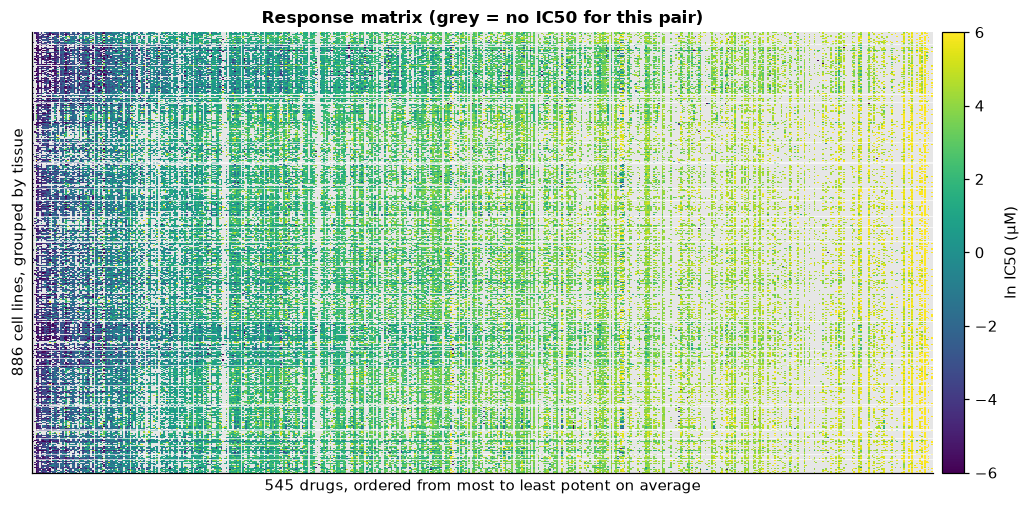

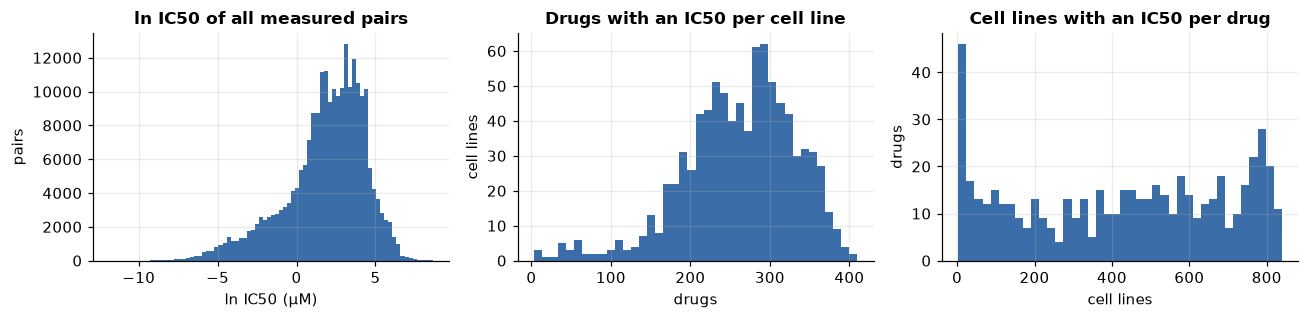

median drugs per cell line: 268    median cell lines per drug: 454


In [3]:
fig, ax = plt.subplots(figsize=(11, 5.2))
plots.response_matrix(table, ax)
plt.show()

per_cell = measured.groupby("cell_line_name").pubchem_id.nunique()
per_drug = measured.groupby("pubchem_id").cell_line_name.nunique()
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].hist(measured.response, bins=80, color=plots.BLUE)
axes[0].set(title="ln IC50 of all measured pairs", xlabel="ln IC50 (µM)", ylabel="pairs")
axes[1].hist(per_cell, bins=40, color=plots.BLUE)
axes[1].set(title="Drugs with an IC50 per cell line", xlabel="drugs", ylabel="cell lines")
axes[2].hist(per_drug, bins=40, color=plots.BLUE)
axes[2].set(title="Cell lines with an IC50 per drug", xlabel="cell lines", ylabel="drugs")
plt.tight_layout()
plt.show()
print(f"median drugs per cell line: {per_cell.median():.0f}    median cell lines per drug: {per_drug.median():.0f}")

### 1.2 What there is to predict

Most of the variation in ln IC50 is between drugs: some drugs are simply more potent than others. A model gets that part for free by predicting each drug's average. DrEval therefore reports *normalized* metrics. Before scoring, it subtracts the prediction of a naive model, `NaiveMeanEffectsPredictor`: the drug's mean plus the mean shift of the cell line's tissue. What is left is the part that actually depends on the individual cell line. The chart shows how the variance splits.

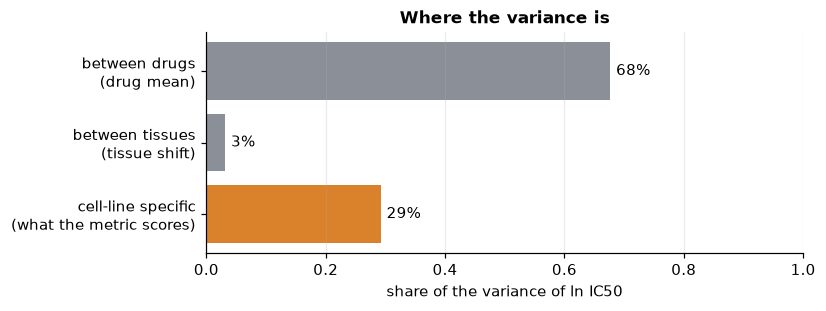

In [4]:
d = measured.copy()
total = d.response.var()
d["after_drug"] = d.response - d.groupby("pubchem_id").response.transform("mean")
d["after_tissue"] = d.after_drug - d.groupby("tissue").after_drug.transform("mean")
shares = pd.Series({
    "between drugs\n(drug mean)": 1 - d.after_drug.var() / total,
    "between tissues\n(tissue shift)": (d.after_drug.var() - d.after_tissue.var()) / total,
    "cell-line specific\n(what the metric scores)": d.after_tissue.var() / total,
})
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(shares.index[::-1], shares.to_numpy()[::-1], color=[plots.ORANGE, plots.GREY, plots.GREY])
for i, v in enumerate(shares.to_numpy()[::-1]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.set(xlim=(0, 1), xlabel="share of the variance of ln IC50", title="Where the variance is")
ax.grid(axis="y", visible=False)
plt.show()

### 1.3 The input: gene expression

The only input of every model is the expression of the L1000 landmark genes, as provided by DrEval. Values are arcsinh-transformed and each gene is standardized on the training cell lines. Expression separates some tissues, most clearly blood and lymphoid lines from solid tumours (left). The metric, however, only rewards differences *within* a tissue.

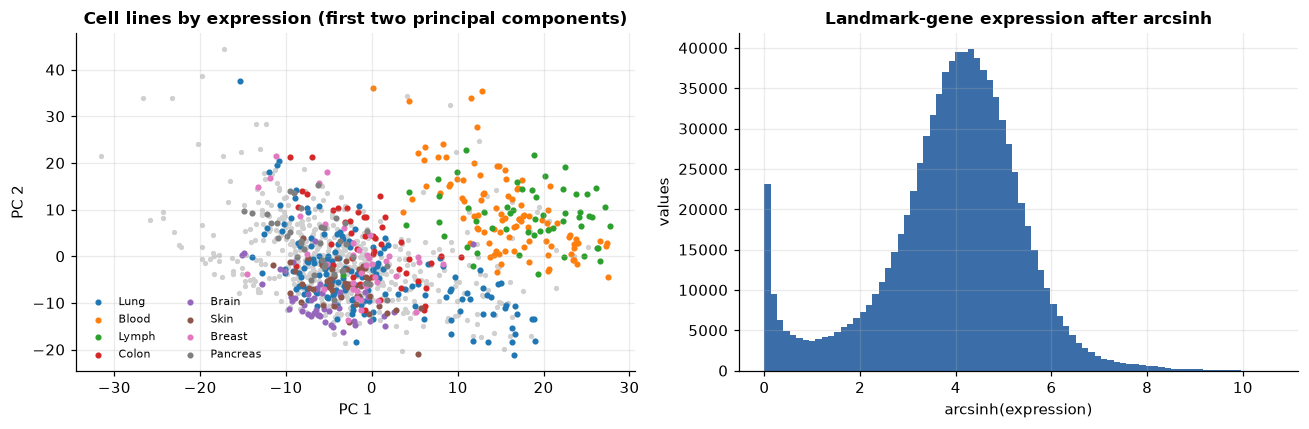

raw expression ranges from 0 to 20,500; arcsinh compresses that to 0.0 to 10.6


In [5]:
tissue = table.drop_duplicates("cell_line_name").set_index("cell_line_name").tissue.reindex(expression.index)
z = (expression - expression.mean()) / expression.std().replace(0, 1)
u, s, _ = np.linalg.svd(z.to_numpy(), full_matrices=False)
pcs = u[:, :2] * s[:2]
top = tissue.value_counts().head(8).index
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pcs[:, 0], pcs[:, 1], s=6, color="#d0d0d0")
for t, c in zip(top, plt.get_cmap("tab10").colors):
    m = (tissue == t).to_numpy()
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=9, color=c, label=t)
axes[0].legend(fontsize=7.5, ncol=2, frameon=False)
axes[0].set(title="Cell lines by expression (first two principal components)", xlabel="PC 1", ylabel="PC 2")
raw = np.sinh(expression.to_numpy()).ravel()
axes[1].hist(expression.to_numpy().ravel(), bins=80, color=plots.BLUE)
axes[1].set(title="Landmark-gene expression after arcsinh", xlabel="arcsinh(expression)", ylabel="values")
plt.tight_layout()
plt.show()
print(f"raw expression ranges from {raw.min():.0f} to {raw.max():,.0f}; arcsinh compresses that to {expression.to_numpy().min():.1f} to {expression.to_numpy().max():.1f}")

### 1.4 The leave-cell-line-out splits

The leaderboard uses 10 fixed splits. In each one, every cell line is in exactly one of train, validation or test, so a model is always tested on cell lines it has never seen. All drugs appear in training. Every model here has a single fixed configuration, so DrEval does no hyperparameter tuning. The ridge is trained on train + validation. The MLP is trained on train + 60 of the 80 validation cell lines; DrEval holds out the other 20 for early stopping. Where a model chooses something (the ridge penalty per drug, the MLP's number of epochs), it does so inside its training data. Every model is tested on the test cell lines only.

In [6]:
rows = []
for k in range(10):
    parts = {r: pd.read_csv(f"{SPLITS}/cv_split_{k}_{r}.csv", usecols=["cell_line_name", "pubchem_id"]) for r in ["train", "validation", "test"]}
    cells = {r: set(p.cell_line_name) for r, p in parts.items()}
    assert not (cells["train"] & cells["test"]) and not (cells["validation"] & cells["test"])
    rows.append({"split": k, **{f"{r} cell lines": len(c) for r, c in cells.items()}, "test pairs": len(parts["test"]),
                 "test drugs seen in training": f"{parts['test'].pubchem_id.isin(set(parts['train'].pubchem_id) | set(parts['validation'].pubchem_id)).mean():.1%}"})
pd.DataFrame(rows).set_index("split")

,train cell lines,validation cell lines,test cell lines,test pairs,test drugs seen in training
split,,,,,
0,718,80,88,23594,100.0%
1,718,80,88,23588,100.0%
2,717,80,89,23612,100.0%
3,717,80,89,23596,100.0%
4,717,80,89,23601,100.0%
5,718,80,88,23588,100.0%
6,718,80,88,23594,100.0%
7,717,80,89,23588,100.0%
8,717,80,89,23597,100.0%


## 2. The models

Both models make the same two choices:

- **Each drug gets its own output.** In LCO every test drug was seen in training, so no drug features are needed and nothing has to generalize across chemistry.
- **Each drug is fitted on its own scale.** The ridge fits each drug separately. The network centres and scales each drug's responses before training. Section 5.2 shows why this matters.

They differ in how a cell line's expression is turned into a prediction: a separate linear model per drug, or one nonlinear representation shared by all drugs. Each is trained on its own, and the ensemble averages their predictions.

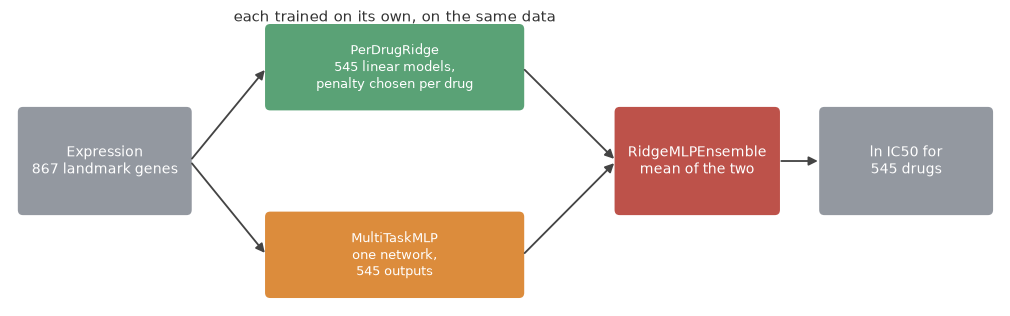

In [7]:
n_genes, n_drugs = expression.shape[1], measured.pubchem_id.nunique()
fig = plots.overview(n_genes, n_drugs)
plt.show()

### 2.1 Per-drug ridge regression

For every drug, a linear regression on the 867 standardized genes, fitted on the cell lines measured for that drug, with an L2 penalty that shrinks the weights. The penalty is chosen per drug from a fixed grid of 14 values by exact leave-one-out error on the drug's training cell lines. For ridge this is a closed-form calculation, so it costs no extra fits. The model is fitted in the dual (cell lines × cell lines) form, which is cheap because there are fewer cell lines than genes.

In [8]:
print("penalty grid (relative to the mean squared norm of a cell line per gene):")
print(np.round(RIDGE_ALPHAS, 3))
print(f"\nin the usual form ||y - Xw||^2 + penalty * ||w||^2 the penalties run from {RIDGE_ALPHAS[0] * n_genes:,.0f} to {RIDGE_ALPHAS[-1] * n_genes:,.0f}")

penalty grid (relative to the mean squared norm of a cell line per gene):
[1.00000e-02 2.20000e-02 4.90000e-02 ... 6.42230e+01 1.42510e+02
 3.16228e+02]

in the usual form ||y - Xw||^2 + penalty * ||w||^2 the penalties run from 9 to 274,169


### 2.2 Multi-task MLP

A plain MLP with one twist in how it is used: the output layer has **one unit per drug**. A cell line's expression goes in once, and the predictions for all drugs come out together.

- The two hidden layers are shared by all drugs, so they are trained on every measurement in the training set.
- Each drug only owns its output unit: a weight vector over the last hidden layer.
- Missing pairs are left out of the loss, so the holes in the response matrix need no imputation.
- Responses are centred and scaled per drug, so the network never has to learn that drugs differ in potency.

All settings are **conventional defaults, not tuned**: two hidden layers of 512 ReLU units, dropout 0.2, Adam at its default learning rate (0.001) with no weight decay, batch size 64. Training stops when the error on DrEval's 20 early-stopping cell lines has not improved for 10 epochs, and the best epoch is kept. Ten networks with different seeds are averaged.

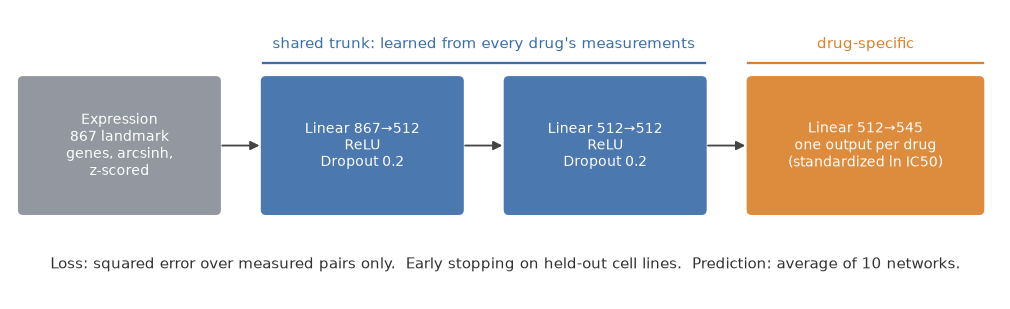

parameters: 986,657 in total = 707,072 shared + 279,585 in the output layer (513 per drug)


hyperparameter,batch_size,depth,dropout,hidden,lr,max_epochs,n_ensemble,patience,seed
value,64.0,2.0,0.2,512.0,0.001,200.0,10.0,10.0,0.0


The whole training loop. The mask is what makes it work on a matrix with holes; the early-stopping cell lines decide when to stop:
```python
def train_network(
    net: nn.Module,
    x: torch.Tensor,
    target: torch.Tensor,
    mask: torch.Tensor,
    x_stop: torch.Tensor,
    target_stop: torch.Tensor,
    mask_stop: torch.Tensor,
    max_epochs: int = 200,
    patience: int = 10,
    batch_size: int = 64,
    lr: float = 1e-3,
) -> tuple[nn.Module, int]:
    """
    Train with Adam on the measured pairs, stopping when the error on held-out cell lines stops improving.

    :param net: network from ``build_network``, already on the device of ``x``
    :param x: (n_cells, n_genes) standardized expression of the training cell lines
    :param target: (n_cells, n_drugs) standardized responses, 0 where unmeasured
    :param mask: (n_cells, n_drugs) 1 where the pair was measured, else 0
    :param x_stop: expression of the early-stopping cell lines
    :param target_stop: their standardized responses
    :param mask_stop: their measured-pair mask
    :param max_epochs: upper limit on passes over the training cell lines
    :param patience: epochs without improvement on the early-stopping cell lines before stopping
    :param batch_size: cell lines per step
    :param lr: Adam learning rate
    :returns: the network restored to its best epoch, in eval mode, and that epoch's number
    """
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    best, best_state, best_epoch, stale = float("inf"), None, 0, 0
    for epoch in range(1, max_epochs + 1):
        net.train()
        perm = torch.randperm(len(x), device=x.device)
        for i in range(0, len(x), batch_size):
            b = perm[i : i + batch_size]
            loss = masked_mse(net(x[b]), target[b], mask[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            err = float(masked_mse(net(x_stop), target_stop, mask_stop))
        if err < best - 1e-6:
            best, best_epoch, stale = err, epoch, 0
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            stale += 1
            if stale >= patience:
                break
    if best_state is not None:
        net.load_state_dict(best_state)
    net.eval()
    return net, best_epoch

```

In [9]:
hp = MultiTaskMLP.get_hyperparameter_set()[0]
fig = plots.architecture(n_genes, n_drugs, hp["hidden"], hp["dropout"], hp["n_ensemble"])
plt.show()

net = build_network(n_genes, n_drugs)
shared = sum(p.numel() for layer in list(net)[:-1] for p in layer.parameters())
head = sum(p.numel() for p in net[-1].parameters())
print(f"parameters: {shared + head:,} in total = {shared:,} shared + {head:,} in the output layer ({head // n_drugs:,} per drug)")
display(pd.Series(hp, name="value").rename_axis("hyperparameter").to_frame().T)
display(Markdown("The whole training loop. The mask is what makes it work on a matrix with holes; the early-stopping cell lines decide when to stop:\n```python\n" + inspect.getsource(train_network) + "\n```"))

### 2.3 The ensemble

`RidgeMLPEnsemble` trains `PerDrugRidge` and `MultiTaskMLP`, each with its own settings, and returns the unweighted mean of their predictions. No weights are fitted, so it uses nothing beyond the training data.

In [10]:
from chocolate.ensemble import COMPONENTS
ENSEMBLE_MEMBERS = [c.get_model_name() for c in COMPONENTS]
print("members:", ", ".join(ENSEMBLE_MEMBERS))
display(Markdown("```python\n" + inspect.getsource(RidgeMLPEnsemble.predict) + "\n```"))

members: PerDrugRidge, MultiTaskMLP


```python
    def predict(
        self,
        cell_line_ids: np.ndarray,
        drug_ids: np.ndarray,
        cell_line_input: FeatureDataset,
        drug_input: FeatureDataset | None = None,
    ) -> np.ndarray:
        """
        Average the components' predictions.

        :param cell_line_ids: cell-line ids
        :param drug_ids: drug ids
        :param cell_line_input: cell-line features
        :param drug_input: not used
        :returns: (n,) predicted ln(IC50)
        """
        return np.mean([p.predict(cell_line_ids, drug_ids, cell_line_input) for p in self.parts], axis=0)

```

## 3. Running the models in DrEval

`run.run_dreval` calls DrEval's own `drug_response_experiment` with the three model classes and the `NaiveMeanEffectsPredictor` baseline, which the normalized metrics need. DrEval reuses splits it finds in the run folder, so the leaderboard splits are copied there first. DrEval skips every model and split that already has predictions, so a finished run is not repeated. Delete `results/final` to run it again: about 15 minutes on one GPU.

In [11]:
run_dir = run.run_dreval(RUN_ID, MODELS, path_data=DATA, path_out=RESULTS, splits_dir=SPLITS)
for m in OURS + [run.BASELINE]:
    print(f"{m:28s} predictions for {run.finished(run_dir, m)} splits")

Run 'final' already has predictions of every model for all 10 splits; not repeating it.
PerDrugRidge                 predictions for 10 splits
MultiTaskMLP                 predictions for 10 splits
RidgeMLPEnsemble             predictions for 10 splits
NaiveMeanEffectsPredictor    predictions for 10 splits


## 4. Performance

### 4.1 DrEval's evaluation

`run.evaluate` calls DrEval's `create_report`, which computes every metric per split and writes an HTML report to the run folder.

In [12]:
evaluation = run.evaluate(RUN_ID, path_data=DATA, path_out=RESULTS)
ours = evaluation.pivot_table(index="CV_split", columns="algorithm", values=METRIC)[OURS]
print(f"DrEval report: {RESULTS}/{RUN_ID}/index.html\n")
print(f"{METRIC} per split:")
ours.round(4)

DrEval report: results/final/index.html

Pearson: normalized per split:


algorithm,PerDrugRidge,MultiTaskMLP,RidgeMLPEnsemble
CV_split,,,
0,0.4552,0.3764,0.4449
1,0.3659,0.3807,0.3858
2,0.4451,0.4660,0.4710
3,0.3856,0.3717,0.3926
4,0.3765,0.4259,0.4155
5,0.3755,0.3665,0.3845
6,0.3853,0.3901,0.4009
7,0.4221,0.3924,0.4228
8,0.4312,0.4540,0.4629


### 4.2 Against the leaderboard

The published leaderboard file contains the per-split scores of every model on the same 10 splits.

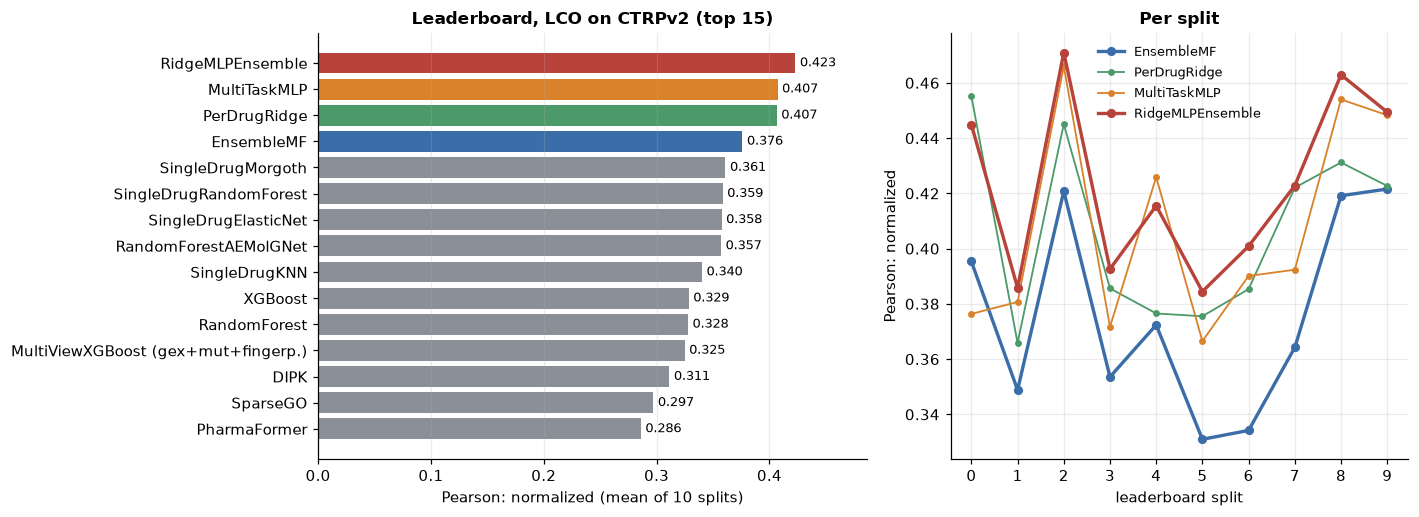

,mean,vs EnsembleMF,splits ahead of EnsembleMF
algorithm,,,
EnsembleMF,0.3761,NaN,NaN
PerDrugRidge,0.4065,0.0304,10.0
MultiTaskMLP,0.4072,0.0311,9.0
RidgeMLPEnsemble,0.4230,0.0469,10.0


In [13]:
lb = pd.read_csv(LEADERBOARD)
lb = lb[(lb.test_mode == "LCO") & (lb.rand_setting == "predictions")]
published = lb.pivot_table(index="CV_split", columns="algorithm", values=METRIC).dropna(axis=1)
board = published.join(ours)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
plots.leaderboard(board.mean(), C, axes[0])
axes[0].set_title("Leaderboard, LCO on CTRPv2 (top 15)")
x = np.arange(10)
for m in ["EnsembleMF"] + OURS:
    axes[1].plot(x, board[m], "o-", color=C[m], label=m, lw=2.2 if m in ("RidgeMLPEnsemble", "EnsembleMF") else 1.2,
                 ms=5 if m in ("RidgeMLPEnsemble", "EnsembleMF") else 3.5)
axes[1].set(title="Per split", xlabel="leaderboard split", ylabel=METRIC, xticks=x)
axes[1].legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "mean": board[["EnsembleMF"] + OURS].mean(),
    "vs EnsembleMF": board[["EnsembleMF"] + OURS].mean() - board["EnsembleMF"].mean(),
    "splits ahead of EnsembleMF": [(board[m] > board["EnsembleMF"]).sum() for m in ["EnsembleMF"] + OURS],
})
summary.loc["EnsembleMF", ["vs EnsembleMF", "splits ahead of EnsembleMF"]] = np.nan
summary.round(4)

### 4.3 Significance

The challenge asks for a significant difference. DrEval's critical-difference analysis uses a Friedman test across the splits, followed by Conover post-hoc tests with Benjamini-Hochberg correction. The same test is applied here, first adding each model to the leaderboard on its own (as it would be submitted), then all three together.

In [14]:
rows = []
for m in OURS:
    b = published.join(ours[[m]])
    con = sp.posthoc_conover_friedman(b, p_adjust="fdr_bh")
    rk = b.rank(axis=1, ascending=False)[m]
    rows.append({"model": m, "mean rank": rk.mean(), "first on (of 10 splits)": int((rk == 1).sum()),
                 "Conover p vs EnsembleMF": con.loc[m, "EnsembleMF"], "Conover p vs NaiveDrugMeanPredictor": con.loc[m, "NaiveDrugMeanPredictor"]})
display(pd.DataFrame(rows).set_index("model").round(4))

stat, p_friedman = friedmanchisquare(*[board[c] for c in board.columns])
con_all = sp.posthoc_conover_friedman(board, p_adjust="fdr_bh")
rk_all = board.rank(axis=1, ascending=False)
print(f"all three added together: Friedman p = {p_friedman:.1e} over {board.shape[1]} models")
print("mean ranks:", ", ".join(f"{m} {rk_all[m].mean():.2f}" for m in OURS + ["EnsembleMF"]))
print(f"Conover p RidgeMLPEnsemble vs EnsembleMF: {con_all.loc['RidgeMLPEnsemble', 'EnsembleMF']:.4f}; "
      f"vs MultiTaskMLP: {con_all.loc['RidgeMLPEnsemble', 'MultiTaskMLP']:.2f}; vs PerDrugRidge: {con_all.loc['RidgeMLPEnsemble', 'PerDrugRidge']:.2f}")
print(f"RidgeMLPEnsemble ahead of MultiTaskMLP on {(board['RidgeMLPEnsemble'] > board['MultiTaskMLP']).sum()} of 10 splits, ahead of PerDrugRidge on {(board['RidgeMLPEnsemble'] > board['PerDrugRidge']).sum()}")

,mean rank,first on (of 10 splits),Conover p vs EnsembleMF,Conover p vs NaiveDrugMeanPredictor
model,,,,
PerDrugRidge,1.0,10,0.0028,0.0
MultiTaskMLP,1.9,9,0.0774,0.0
RidgeMLPEnsemble,1.0,10,0.0028,0.0


all three added together: Friedman p = 5.0e-53 over 37 models
mean ranks: PerDrugRidge 2.50, MultiTaskMLP 3.20, RidgeMLPEnsemble 1.20, EnsembleMF 5.50
Conover p RidgeMLPEnsemble vs EnsembleMF: 0.0000; vs MultiTaskMLP: 0.02; vs PerDrugRidge: 0.14
RidgeMLPEnsemble ahead of MultiTaskMLP on 9 of 10 splits, ahead of PerDrugRidge on 9


**What this shows.** Added to the leaderboard on its own, `PerDrugRidge` and `RidgeMLPEnsemble` each rank first on all 10 splits. That gives Conover p = 0.003 against `EnsembleMF`; with 10 splits, a model that is first on every split cannot get a smaller value here. `MultiTaskMLP` ranks first on 9 of 10 splits, but its p = 0.077 is not significant. All three are far above `NaiveDrugMeanPredictor`, so the "send us chocolate" clause is not at risk.

With all three added together, the ensemble has the best mean rank (1.2) and is ahead of each member on 9 of 10 splits. The Conover test separates it from the MLP (p = 0.02) but not from the ridge (p = 0.14).

### 4.4 Other metrics, and a look at the predictions

The table compares every metric DrEval reports. The scatter shows all test pairs of the ensemble after subtracting the naive reference, which is the view the normalized metric scores.

algorithm,PerDrugRidge,MultiTaskMLP,RidgeMLPEnsemble,EnsembleMF,NaiveMeanEffectsPredictor
Pearson: normalized,0.4065,0.4072,0.4230,0.3761,0.0000
Spearman: normalized,0.3970,0.3953,0.4113,0.3514,0.0000
Kendall: normalized,0.2824,0.2817,0.2934,0.2488,0.0000
R^2: normalized,0.1637,0.1633,0.1774,0.1269,-0.0011
Pearson,0.8683,0.8677,0.8703,0.8623,0.8389
R^2,0.7537,0.7524,0.7571,0.7415,0.7034
RMSE,1.2589,1.2620,1.2501,1.2894,1.3791
MAE,0.8428,0.8464,0.8364,0.8741,0.9448


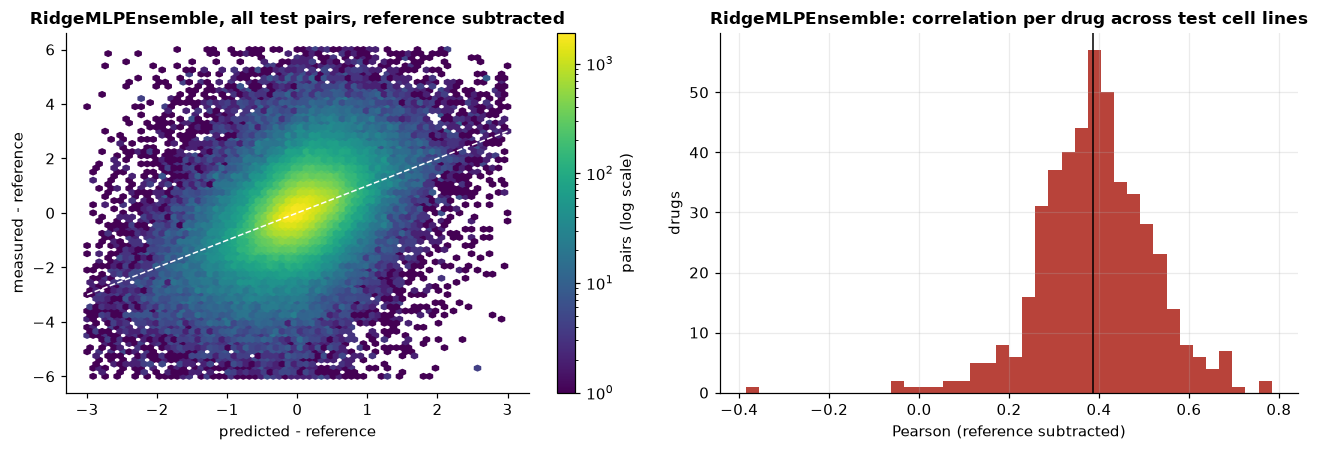

median per-drug correlation 0.387; positive for 99% of 470 drugs


In [15]:
cols = [METRIC, "Spearman: normalized", "Kendall: normalized", "R^2: normalized", "Pearson", "R^2", "RMSE", "MAE"]
compare = evaluation.groupby("algorithm")[cols].mean().T[OURS]
compare["EnsembleMF"] = lb[lb.algorithm == "EnsembleMF"][cols].mean()
compare[run.BASELINE] = lb[lb.algorithm == run.BASELINE][cols].mean()
display(compare.round(4))

folds = [A.Fold(SPLITS, k, expression, run_dir=f"{RESULTS}/{RUN_ID}") for k in range(10)]
preds = A.load_all_predictions(f"{RESULTS}/{RUN_ID}", OURS, folds)
pairs = pd.concat([A.normalized_pairs(f, {"RidgeMLPEnsemble": p}) for f, p in zip(folds, preds["RidgeMLPEnsemble"])])
per_drug_ens = A.per_drug_table(folds, {"RidgeMLPEnsemble": preds["RidgeMLPEnsemble"]})["RidgeMLPEnsemble"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
hb = axes[0].hexbin(pairs.RidgeMLPEnsemble, pairs.measured, gridsize=70, bins="log", cmap="viridis", extent=(-3, 3, -6, 6))
plt.colorbar(hb, ax=axes[0], label="pairs (log scale)")
axes[0].plot([-3, 3], [-3, 3], color="white", lw=1, ls="--")
axes[0].set(title="RidgeMLPEnsemble, all test pairs, reference subtracted", xlabel="predicted - reference", ylabel="measured - reference")
axes[0].grid(False)
axes[1].hist(per_drug_ens, bins=40, color=C["RidgeMLPEnsemble"])
axes[1].axvline(per_drug_ens.median(), color="black", lw=1)
axes[1].set(title="RidgeMLPEnsemble: correlation per drug across test cell lines", xlabel="Pearson (reference subtracted)", ylabel="drugs")
plt.tight_layout()
plt.show()
print(f"median per-drug correlation {per_drug_ens.median():.3f}; positive for {(per_drug_ens > 0).mean():.0%} of {len(per_drug_ens)} drugs")

## 5. Why do these models beat EnsembleMF?

`EnsembleMF` looks quite different from the models here: a two-tower matrix factorization with drug fingerprints, bias terms and an interaction head. In the LCO setting, though, its structure is close to theirs. Every test drug was seen in training, so each drug's latent vector is fixed, and apart from the small interaction head it predicts a drug as

> a shared encoding of the cell line's expression · that drug's vector + the drug's bias

That is a shared cell-line encoder with a **per-drug linear readout**, like the network here. The table lists the differences that remain.

| | EnsembleMF | Models here |
|---|---|---|
| Training target | raw ln IC50, one squared error over all pairs | each drug on its own scale (fitted separately, or standardized per drug) |
| Per-drug part | 128-number vector from a fingerprint encoder plus a free embedding | a full linear model per drug (ridge), or a 512-number output unit (MLP) |
| Regularization | early stopping on validation error, light dropout and weight decay | penalty chosen per drug (ridge); early stopping, light dropout and seed averaging (MLP) |
| Expression features | rank-transformed landmark genes | arcsinh landmark genes |

This section looks first at where in the predictions the advantage sits (5.1), then at the one choice both models share (5.2), then at each model (5.3–5.4), and finally at the ensemble (5.5). `EnsembleMF`'s predictions are the published ones from the leaderboard (`true_vs_pred.csv` in the leaderboard archive on Zenodo). Scores use DrEval's normalized Pearson. The helper used below reproduces DrEval's numbers exactly; the next cell checks this for the three models here and for the published `EnsembleMF`.

In [16]:
check = pd.DataFrame({m: [f.score(p) for f, p in zip(folds, preds[m])] for m in OURS})
assert np.allclose(check.to_numpy(), ours[OURS].to_numpy(), atol=1e-6)
print("the notebook's scorer matches DrEval's report on every split for", ", ".join(OURS))

preds["EnsembleMF"] = [A.published_predictions(PUBLISHED_EMF, f) for f in folds]
emf_check = np.array([f.score(p) for f, p in zip(folds, preds["EnsembleMF"])])
print(f"published EnsembleMF predictions scored here: {emf_check.mean():.4f}; published leaderboard score: {published['EnsembleMF'].mean():.4f}; "
      f"largest per-split difference {np.abs(emf_check - published['EnsembleMF'].to_numpy()).max():.4f}")

the notebook's scorer matches DrEval's report on every split for PerDrugRidge, MultiTaskMLP, RidgeMLPEnsemble


published EnsembleMF predictions scored here: 0.3761; published leaderboard score: 0.3761; largest per-split difference 0.0000


### 5.1 Where in the prediction is the advantage?

Some cell lines are more sensitive to almost every drug. A model could score well by predicting only that general level. To see what each model contributes, every prediction is split into two parts. The *general* part is the cell line's mean deviation from the naive reference across all drugs. The *drug-specific* part is the rest. Each part is scored separately. "Measured general level" uses the measured level of each test cell line, so it is the best any general-only predictor could do.

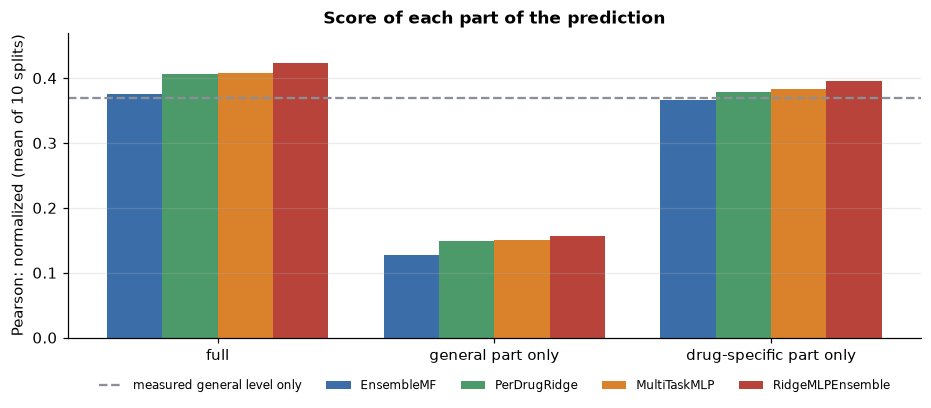

measured general level only: 0.3690


,corr. of predicted and measured level,drug-specific part only,full,general part only
EnsembleMF,0.3296,0.3668,0.3761,0.1266
MultiTaskMLP,0.3967,0.3831,0.4072,0.1512
PerDrugRidge,0.3985,0.3786,0.4065,0.1490
RidgeMLPEnsemble,0.4122,0.3952,0.4230,0.1562


In [17]:
models_51 = ["EnsembleMF"] + OURS
rows, ceilings = [], []
for i, f in enumerate(folds):
    level = A.observed_general_level(f)
    ceilings.append(f.score(f.baseline + level[:, None]))
    row = {}
    for m in models_51:
        p = preds[m][i]
        general, lv = A.split_general_specific(f, p)
        row[(m, "full")] = f.score(p)
        row[(m, "general part only")] = f.score(general)
        row[(m, "drug-specific part only")] = f.score(p - lv[:, None])
        row[(m, "corr. of predicted and measured level")] = np.corrcoef(lv, level)[0, 1]
    rows.append(row)
parts = pd.Series(pd.DataFrame(rows).mean().to_numpy(), index=pd.MultiIndex.from_tuples(rows[0].keys())).unstack()
ceiling = float(np.mean(ceilings))

fig, ax = plt.subplots(figsize=(10, 3.6))
labels = ["full", "general part only", "drug-specific part only"]
w = 0.2
for i, m in enumerate(models_51):
    vals = parts.loc[m, labels].to_numpy()
    ax.bar(np.arange(3) + (i - 1.5) * w, vals, w, color=C[m], label=m)
ax.axhline(ceiling, color=plots.GREY, ls="--", label="measured general level only")
ax.set_xticks(range(3))
ax.set_xticklabels(labels)
ax.set(ylabel=f"{METRIC} (mean of 10 splits)", title="Score of each part of the prediction")
ax.legend(frameon=False, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_ylim(0, 0.47)
ax.grid(axis="x", visible=False)
plt.show()
print(f"measured general level only: {ceiling:.4f}")
parts.round(4)

**What this shows.**

- **Both models are ahead in both parts.** `EnsembleMF`'s general part scores 0.127 against 0.149 (ridge) and 0.151 (MLP), and its predicted general level correlates less with the measured one (0.33 against 0.40). In the drug-specific part `EnsembleMF` scores 0.367, against 0.379 (ridge) and 0.383 (MLP).
- **The two models are close in both parts.** The MLP is slightly ahead in the drug-specific part, and they are level in the general part.
- **General sensitivity alone is not enough.** Even the measured level of each test cell line, which no model can know, scores only 0.369, below every full model here.
- **The ensemble improves both parts** (0.156 general, 0.395 drug-specific).

### 5.2 What both models share: each drug on its own scale

`EnsembleMF` is trained with one squared error over all pairs, on raw ln IC50. Under that loss a drug's weight grows with the spread of its responses: a drug whose ln IC50 varies over 4 units counts about 16 times as much as one that varies over 1 unit. Drugs differ a lot in spread (left), so a handful of high-variance drugs dominate the loss. The challenge metric, however, pools all pairs after subtracting the reference, and drugs with modest spread make up most of it.

The models here do not have this imbalance. The ridge fits each drug separately, and the network standardizes each drug before training. If the imbalance matters, `EnsembleMF` should be furthest behind on drugs with little spread, and nearly level on the drugs with the most. The right panel checks this.

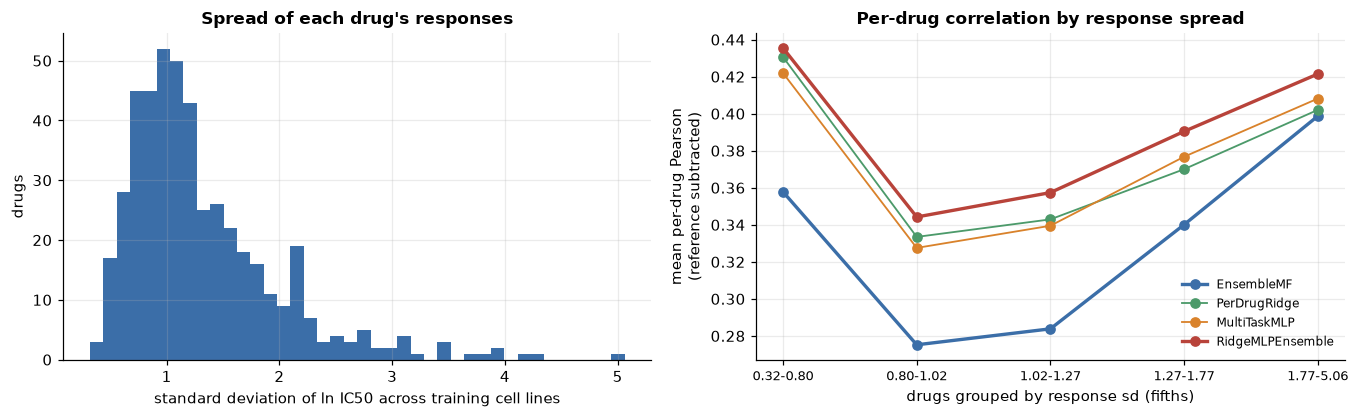

response sd ranges from 0.32 to 5.06 (median 1.14); the top 10% of drugs carry 39% and the top 25% 63% of the within-drug variance
gap of the two models (mean) over EnsembleMF, lowest to highest spread: +0.068, +0.055, +0.057, +0.033, +0.006
PerDrugRidge     ahead of EnsembleMF on 80% of drugs; Spearman of the gain with response sd -0.40
MultiTaskMLP     ahead of EnsembleMF on 85% of drugs; Spearman of the gain with response sd -0.38
RidgeMLPEnsemble ahead of EnsembleMF on 90% of drugs; Spearman of the gain with response sd -0.36


In [18]:
per_drug = A.per_drug_table(folds, {m: preds[m] for m in ["EnsembleMF"] + OURS}).dropna()
sd = per_drug["response sd"]
var_share = (sd**2).sort_values(ascending=False).cumsum() / (sd**2).sum()
per_drug["spread"] = pd.qcut(sd, 5)
by_sd = per_drug.groupby("spread", observed=True)[["EnsembleMF"] + OURS].mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
axes[0].hist(sd, bins=40, color=plots.BLUE)
axes[0].set(title="Spread of each drug's responses", xlabel="standard deviation of ln IC50 across training cell lines", ylabel="drugs")
xq = np.arange(len(by_sd))
for m in ["EnsembleMF"] + OURS:
    axes[1].plot(xq, by_sd[m], "o-", color=C[m], label=m, lw=2.2 if m in ("EnsembleMF", "RidgeMLPEnsemble") else 1.2)
axes[1].set_xticks(xq)
axes[1].set_xticklabels([f"{iv.left:.2f}-{iv.right:.2f}" for iv in by_sd.index], fontsize=8.5)
axes[1].set(title="Per-drug correlation by response spread", xlabel="drugs grouped by response sd (fifths)", ylabel="mean per-drug Pearson\n(reference subtracted)")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
n10 = len(sd) // 10
print(f"response sd ranges from {sd.min():.2f} to {sd.max():.2f} (median {sd.median():.2f}); "
      f"the top 10% of drugs carry {var_share.iloc[n10 - 1]:.0%} and the top 25% {var_share.iloc[len(sd) // 4 - 1]:.0%} of the within-drug variance")
gap = by_sd[SINGLE].mean(axis=1) - by_sd["EnsembleMF"]
print("gap of the two models (mean) over EnsembleMF, lowest to highest spread:", ", ".join(f"{g:+.3f}" for g in gap))
for m in OURS:
    g = per_drug[m] - per_drug["EnsembleMF"]
    print(f"{m:16s} ahead of EnsembleMF on {(g > 0).mean():.0%} of drugs; Spearman of the gain with response sd {spearmanr(g, sd)[0]:+.2f}")

**What this shows.** The pattern fits the loss-weighting explanation:

- **A few drugs dominate the variance.** Response spreads range from 0.32 to 5.06, and the top 25% of drugs carry 63% of the within-drug variance. A single raw-scale squared error is weighted the same way.
- **`EnsembleMF` is level on the drugs it weights most.** On the most variable fifth of drugs the two models lead it by only 0.006. On the other four fifths they lead by 0.03–0.07.
- **The same holds drug by drug.** For the ridge, the MLP and their average, the gain over `EnsembleMF` shrinks as the drug's spread grows (Spearman −0.36 to −0.40).

This is a correlation, not a controlled test. Drugs with a wider spread may differ in other ways too, for example in how much signal they carry. The direct test would be to retrain `EnsembleMF` on per-drug standardized targets. It was started here but not finished: on the one split that completed it gained 0.006 (0.391 to 0.397). That is a hint that the target is part of the story, but not all of it.

### 5.3 Per-drug ridge: the right amount of shrinkage

With 867 genes and a median of about 450 cell lines per drug, a linear model needs strong regularization. The left panel shows how much the score depends on the penalty when one penalty is used for every drug. The right panel shows which penalties the leave-one-out rule picks per drug.

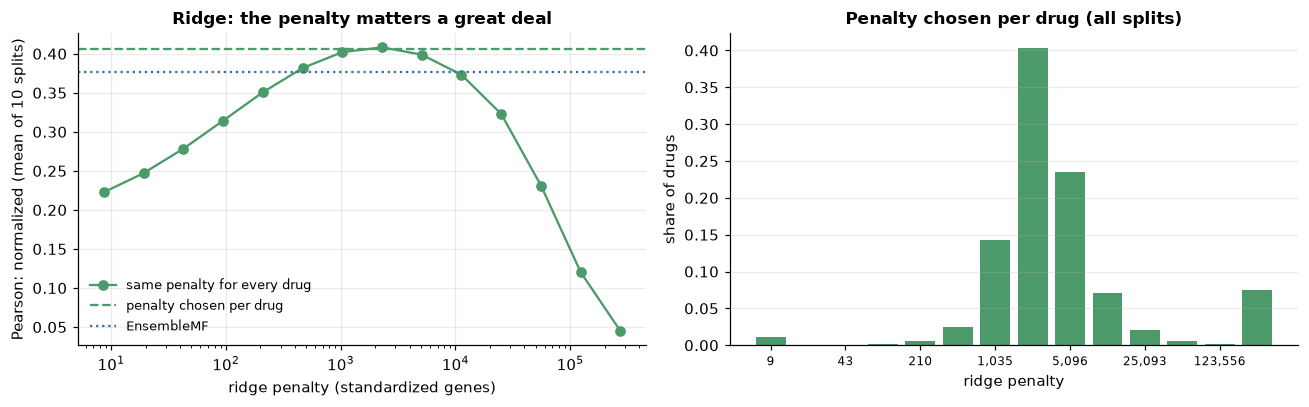

best single penalty 2,297: 0.4082; per-drug choice: 0.4065; penalty 5x smaller: 0.3817; 11x smaller: 0.3506; 5x larger: 0.3730; smallest penalty: 0.2227
median chosen penalty 2,297


In [19]:
def ridge_path_scores():
    out = []
    for f in folds:
        _, path, chosen = A.fit_per_drug_ridge(f, return_path=True)
        out.append({"path_scores": [f.score(p) for p in path], "chosen": chosen})
    return out

ridge_path = A.cached(f"{CACHE}/ridge_path.pkl", ridge_path_scores)
penalties = RIDGE_ALPHAS * n_genes
path_scores = np.mean([r["path_scores"] for r in ridge_path], axis=0)
chosen = np.concatenate([r["chosen"] for r in ridge_path])
chosen = chosen[chosen >= 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].semilogx(penalties, path_scores, "o-", color=C["PerDrugRidge"], label="same penalty for every drug")
axes[0].axhline(ours["PerDrugRidge"].mean(), color=C["PerDrugRidge"], ls="--", label="penalty chosen per drug")
axes[0].axhline(board["EnsembleMF"].mean(), color=C["EnsembleMF"], ls=":", label="EnsembleMF")
axes[0].set(title="Ridge: the penalty matters a great deal", xlabel="ridge penalty (standardized genes)", ylabel=f"{METRIC} (mean of 10 splits)")
axes[0].legend(frameon=False, fontsize=8.5)
counts = np.bincount(chosen, minlength=len(penalties))
axes[1].bar(np.arange(len(penalties)), counts / counts.sum(), color=C["PerDrugRidge"])
axes[1].set_xticks(np.arange(len(penalties))[::2])
axes[1].set_xticklabels([f"{p:,.0f}" for p in penalties[::2]], fontsize=8)
axes[1].set(title="Penalty chosen per drug (all splits)", xlabel="ridge penalty", ylabel="share of drugs")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
best = int(np.argmax(path_scores))
print(f"best single penalty {penalties[best]:,.0f}: {path_scores[best]:.4f}; per-drug choice: {ours['PerDrugRidge'].mean():.4f}; "
      f"penalty {penalties[best] / penalties[best - 2]:.0f}x smaller: {path_scores[best - 2]:.4f}; {penalties[best] / penalties[best - 3]:.0f}x smaller: {path_scores[best - 3]:.4f}; "
      f"{penalties[best + 2] / penalties[best]:.0f}x larger: {path_scores[best + 2]:.4f}; smallest penalty: {path_scores[0]:.4f}")
print(f"median chosen penalty {np.median(penalties[chosen]):,.0f}")

**What this shows.** For ridge, the amount of shrinkage is what matters:

- **The penalty level makes or breaks it.** With one penalty for every drug, the score runs from 0.22 (weakest penalty) to 0.408 (penalty of about 2,300). It falls below `EnsembleMF` with a penalty about 10× too small or 5× too large.
- **Choosing per drug adds nothing.** The per-drug choice lands on that same penalty for most drugs (median 2,297) and scores 0.407, no better than the best shared penalty.
- **Ridge gives up where it finds no signal.** About 8% of the per-drug fits pick the largest penalty, which amounts to predicting the drug's mean.

With about 870 genes and a few hundred cell lines per drug, the data supports only a heavily shrunk linear model. `EnsembleMF` also reads each drug out linearly, but from a learned 128-number encoding fitted with a raw-scale loss and stopped early. A plain, well-shrunk linear model on the genes themselves beats it on all 10 splits. DrEval's own per-drug elastic net (`SingleDrugElasticNet`) scores 0.358. Its penalty grid and L1 term differ from the ridge here, and this notebook does not test which difference matters.

### 5.4 Multi-task MLP: sharing across drugs

The network is the model here that shares across drugs: its two hidden layers are fitted on every drug's measurements. The premise is that drug responses share structure. They do: after removing each drug's mean, the responses of two drugs across cell lines are positively correlated on average, and a handful of directions explain much of the matrix. Shuffling each drug's values across cell lines, which keeps every drug's own distribution, removes that structure.

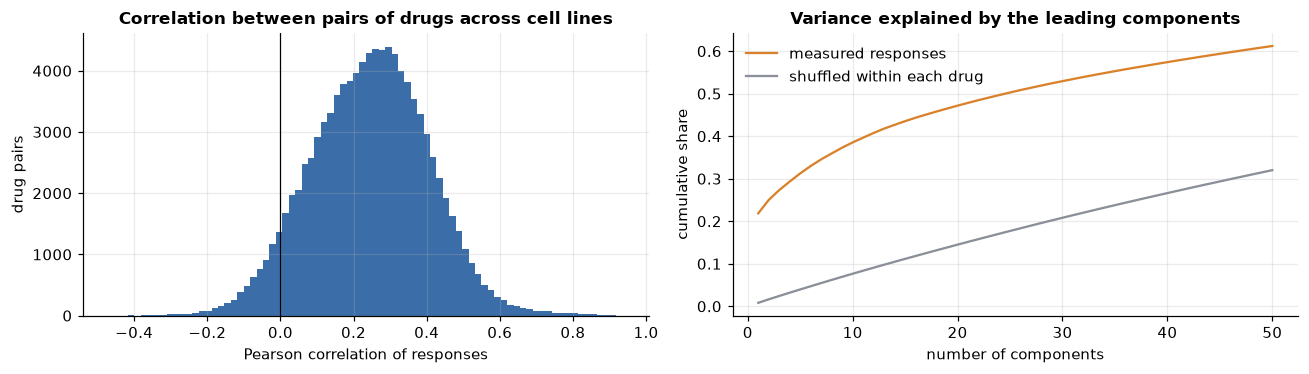

mean correlation between two drugs: 0.25; positive for 94% of drug pairs
first component explains 22% of the variance (shuffled: 0.8%); first 20 explain 47% (shuffled: 15%)


In [20]:
f0 = folds[0]
resid = (f0.y_train - f0.drug_mean) / np.nanstd(f0.y_train, axis=0)
corr = pd.DataFrame(resid).corr(min_periods=50).to_numpy()
upper = corr[np.triu_indices_from(corr, 1)]
upper = upper[~np.isnan(upper)]

def spectrum(mat):
    s = np.linalg.svd(np.nan_to_num(mat), compute_uv=False) ** 2
    return np.cumsum(s) / s.sum()

rng = np.random.default_rng(0)
shuffled = resid.copy()
for j in range(shuffled.shape[1]):
    obs = ~np.isnan(shuffled[:, j])
    shuffled[obs, j] = rng.permutation(shuffled[obs, j])
real, null = spectrum(resid), spectrum(shuffled)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(upper, bins=80, color=plots.BLUE)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(title="Correlation between pairs of drugs across cell lines", xlabel="Pearson correlation of responses", ylabel="drug pairs")
axes[1].plot(range(1, 51), real[:50], color=C["MultiTaskMLP"], label="measured responses")
axes[1].plot(range(1, 51), null[:50], color=plots.GREY, label="shuffled within each drug")
axes[1].set(title="Variance explained by the leading components", xlabel="number of components", ylabel="cumulative share")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"mean correlation between two drugs: {upper.mean():.2f}; positive for {(upper > 0).mean():.0%} of drug pairs")
print(f"first component explains {real[0]:.0%} of the variance (shuffled: {null[0]:.1%}); first 20 explain {real[19]:.0%} (shuffled: {null[19]:.0%})")

**Does training drugs together help the network?** A fixed set of 40 randomly chosen drugs is scored while the number of drugs trained alongside them grows: each drug in its own network, the 40 together, then 100, 250 and all 545 drugs in one network. Architecture, settings and the scored pairs are identical in every case (three splits, five seeds each). Per-drug ridge on the same 40 drugs is the reference.

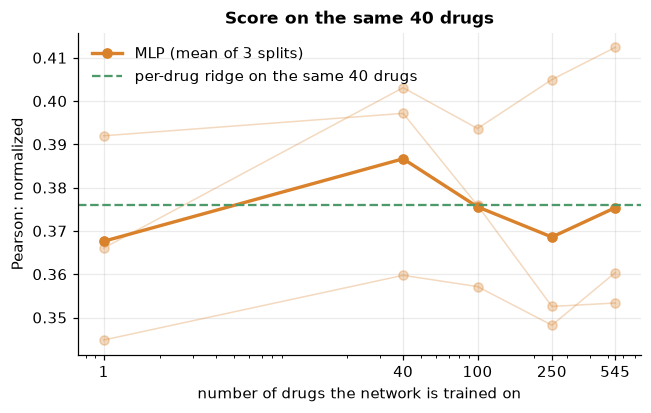

,per-drug ridge,1,40,100,250,545
split,,,,,,
0,0.3887,0.3920,0.3972,0.3759,0.3526,0.3533
1,0.3678,0.3448,0.3597,0.3571,0.3482,0.3604
2,0.3717,0.3660,0.4031,0.3937,0.4050,0.4124


In [21]:
def curve_all():
    targets = np.sort(np.random.default_rng(0).choice(len(folds[0].drugs), 40, replace=False))
    return pd.DataFrame([A.cotraining_curve(folds[k], targets, [40, 100, 250, 545], n_seeds=5) for k in range(3)])

curve = A.cached(f"{CACHE}/cotraining_curve.pkl", curve_all)
nets_only = curve.drop(columns="per-drug ridge")
xs = [1, 40, 100, 250, 545]
fig, ax = plt.subplots(figsize=(6.6, 3.8))
for k in range(len(curve)):
    ax.plot(xs, nets_only.iloc[k], "o-", color=C["MultiTaskMLP"], alpha=0.3, lw=1)
ax.plot(xs, nets_only.mean(), "o-", color=C["MultiTaskMLP"], lw=2.2, label="MLP (mean of 3 splits)")
ax.axhline(curve["per-drug ridge"].mean(), color=C["PerDrugRidge"], ls="--", label="per-drug ridge on the same 40 drugs")
ax.set_xscale("log")
ax.set_xticks(xs)
ax.set_xticklabels(xs)
ax.set(title="Score on the same 40 drugs", xlabel="number of drugs the network is trained on", ylabel=METRIC)
ax.legend(frameon=False, loc="upper left")
plt.show()
curve.rename(columns={"1 (one network per drug)": "1"}).assign(split=range(len(curve))).set_index("split").round(4)

**What the output layer learns.** Each drug's output unit is a weight vector over the last hidden layer. If the shared layers encode features that several drugs use, drugs with similar response patterns should end up with similar weight vectors. The plot compares, for every pair of drugs, the cosine similarity of their output weights (averaged over the 10 networks of split 0) with the correlation of their measured responses.

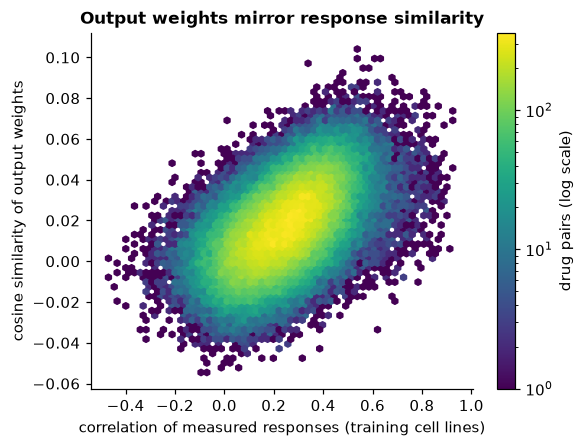

Pearson 0.54, Spearman 0.55 over 100,388 drug pairs


In [22]:
def weight_similarity():
    _, nets = A.fit_multitask(f0, n_seeds=10, return_nets=True)
    sims = []
    for n in nets:
        w = torch.nn.functional.normalize(n[-1].weight.detach(), dim=1)
        sims.append((w @ w.T).cpu().numpy())
    return np.mean(sims, axis=0)

sim = A.cached(f"{CACHE}/weight_similarity.pkl", weight_similarity)
iu = np.triu_indices_from(corr, 1)
ok = ~np.isnan(corr[iu])
a, b = corr[iu][ok], sim[iu][ok]
fig, ax = plt.subplots(figsize=(5.6, 4.2))
hb = ax.hexbin(a, b, gridsize=60, bins="log", cmap="viridis")
plt.colorbar(hb, ax=ax, label="drug pairs (log scale)")
ax.set(title="Output weights mirror response similarity", xlabel="correlation of measured responses (training cell lines)", ylabel="cosine similarity of output weights")
ax.grid(False)
plt.show()
print(f"Pearson {np.corrcoef(a, b)[0, 1]:.2f}, Spearman {spearmanr(a, b)[0]:.2f} over {len(a):,} drug pairs")

**What this shows.** With default settings, training drugs together does not give the network a clear advantage:

- **More drugs do not reliably help.** One drug per network scores 0.368 on these 40 drugs and all 545 together score 0.375, about level with per-drug ridge (0.376). The best point is 40 drugs (0.387).
- **The three splits disagree.** Split 2 improves steadily with more drugs (0.366 to 0.412), split 0 gets worse (0.392 to 0.353), and split 1 stays flat. Each network stops on DrEval's 20 early-stopping cell lines, and with so few cell lines the stopping point is noisy. That noise is as large as any effect of sharing here.
- **The shared layers still reflect related drugs.** Drugs whose responses are correlated get somewhat similar output weights (correlation 0.54).

So with default settings the network ends up about level with ridge, and the multi-task design does not clearly add to its score. Its value here is that it makes different errors from ridge, which the ensemble uses (5.5). An earlier version with a larger network, heavier regularization and a fixed 50 epochs did show a clear benefit from sharing. Its settings were chosen partly with the test splits in view, so it is not used here.

### 5.5 Why averaging helps

Averaging only helps if the models make different mistakes. The left panel shows how strongly the models' normalized predictions agree with each other, pooled over all test pairs of all splits. The right panel compares the two models with their average.

For two predictions that correlate equally well with the truth, the correlation of their average rises as they agree less: with correlation *r* to the truth each and *ρ* with each other, the average reaches *r* · √(2 / (1 + ρ)). At ρ = 1 averaging changes nothing; at ρ = 0.83 it multiplies the correlation by about 1.04.

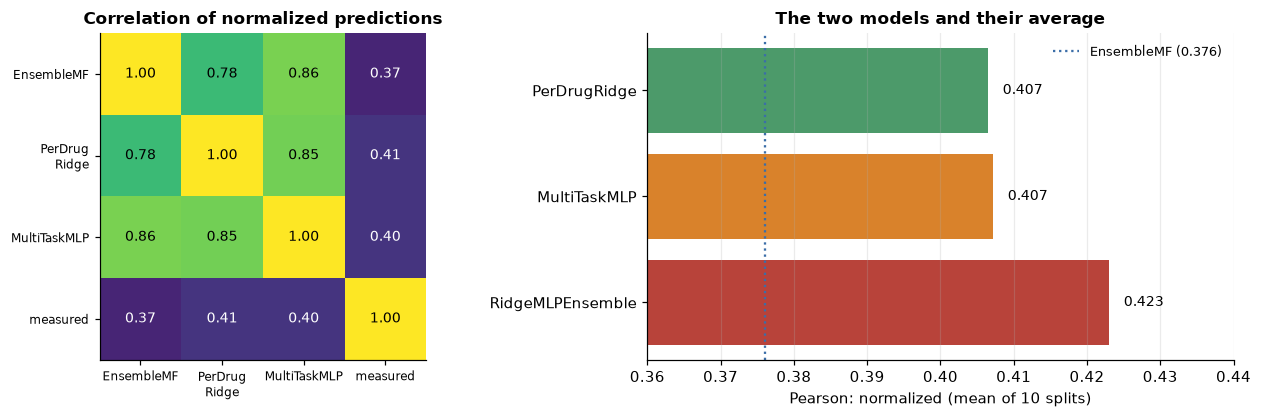

agreement of ridge and MLP: rho = 0.85; pooled correlation with the measured values: ridge 0.405, MLP 0.405, average 0.421 (formula with their mean r: 0.421)
average minus the better of the two on each split: +0.0027 on average, positive on 8 of 10 splits
RidgeMLPEnsemble (trained in its own DrEval run) vs the mean of the separate PerDrugRidge and MultiTaskMLP runs: largest difference 0.0000 ln IC50; scores 0.4230 vs 0.4230
MultiTaskMLP ahead of PerDrugRidge on 43% of 470 drugs
RidgeMLPEnsemble ahead of the better of its two members on 62% of drugs, ahead of the worse on 100%


In [23]:
names = ["EnsembleMF"] + SINGLE
allpairs = pd.concat([A.normalized_pairs(f, {m: preds[m][i] for m in names + ["RidgeMLPEnsemble"]}) for i, f in enumerate(folds)])
cm = allpairs[names + ["measured"]].corr()
rho = cm.loc["PerDrugRidge", "MultiTaskMLP"]
r_pooled = cm.loc[SINGLE, "measured"].mean()
expected = r_pooled * np.sqrt(2 / (1 + rho))
actual = allpairs[["RidgeMLPEnsemble", "measured"]].corr().iloc[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].imshow(cm.to_numpy(), cmap="viridis", vmin=0.3, vmax=1)
labels = [n.replace("PerDrug", "PerDrug\n") for n in cm.columns]
axes[0].set_xticks(range(len(cm)))
axes[0].set_yticks(range(len(cm)))
axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_yticklabels(labels, fontsize=8)
for i in range(len(cm)):
    for j in range(len(cm)):
        axes[0].text(j, i, f"{cm.iat[i, j]:.2f}", ha="center", va="center", color="white" if cm.iat[i, j] < 0.75 else "black", fontsize=9)
axes[0].set_title("Correlation of normalized predictions")
axes[0].grid(False)
bars = ours[OURS].mean()
axes[1].barh(range(3), bars.to_numpy()[::-1], color=[C[m] for m in OURS[::-1]])
for yy, v in enumerate(bars.to_numpy()[::-1]):
    axes[1].text(v + 0.002, yy, f"{v:.3f}", va="center", fontsize=9)
axes[1].axvline(board["EnsembleMF"].mean(), color=C["EnsembleMF"], ls=":", label=f"EnsembleMF ({board['EnsembleMF'].mean():.3f})")
axes[1].set_yticks(range(3))
axes[1].set_yticklabels(OURS[::-1])
axes[1].set(xlim=(0.36, 0.44), xlabel=f"{METRIC} (mean of 10 splits)", title="The two models and their average")
axes[1].legend(frameon=False, fontsize=8.5, loc="upper right")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"agreement of ridge and MLP: rho = {rho:.2f}; pooled correlation with the measured values: ridge {cm.loc['PerDrugRidge', 'measured']:.3f}, "
      f"MLP {cm.loc['MultiTaskMLP', 'measured']:.3f}, average {actual:.3f} (formula with their mean r: {expected:.3f})")
gain = ours["RidgeMLPEnsemble"] - ours[SINGLE].max(axis=1)
print(f"average minus the better of the two on each split: {gain.mean():+.4f} on average, positive on {(gain > 0).sum()} of 10 splits")
mean_members = [np.mean([preds[m][i] for m in ENSEMBLE_MEMBERS], axis=0) for i in range(10)]
diff = np.nanmax([np.nanmax(np.abs(preds["RidgeMLPEnsemble"][i] - mean_members[i])) for i in range(10)])
print(f"RidgeMLPEnsemble (trained in its own DrEval run) vs the mean of the separate {' and '.join(ENSEMBLE_MEMBERS)} runs: "
      f"largest difference {diff:.4f} ln IC50; scores {ours['RidgeMLPEnsemble'].mean():.4f} vs {np.mean([f.score(p) for f, p in zip(folds, mean_members)]):.4f}")
print(f"MultiTaskMLP ahead of PerDrugRidge on {(per_drug.MultiTaskMLP > per_drug.PerDrugRidge).mean():.0%} of {len(per_drug)} drugs")
print(f"RidgeMLPEnsemble ahead of the better of its two members on {(per_drug['RidgeMLPEnsemble'] > per_drug[ENSEMBLE_MEMBERS].max(axis=1)).mean():.0%} of drugs, "
      f"ahead of the worse on {(per_drug['RidgeMLPEnsemble'] > per_drug[ENSEMBLE_MEMBERS].min(axis=1)).mean():.0%}")

**What this shows.**

- **The two models agree only partly.** Their normalized predictions correlate 0.85 with each other. The default network is closer to `EnsembleMF` (0.86) than the ridge is (0.78), which fits its being the more similar kind of model. Each correlates about 0.405 with the measured values.
- **The gain is what disagreement predicts.** With ρ = 0.85, the formula above turns their correlation with the truth (0.405) into 0.421, which is exactly what the average reaches. There is no fitted weight and no extra trick: the average gains only because the two models make different errors.
- **The gain is small but fairly consistent.** On each split the average beats the better of its two members on 8 of 10 splits, and beats each member on 9 of 10. Averaged over splits it is +0.016 above either model.
- **Neither member is best everywhere.** Per drug, the MLP beats ridge on 43% of drugs and ridge wins on the rest. The ensemble beats the better of its two members on 62% of drugs and the worse on all of them.
- **The DrEval ensemble is exactly the average.** It was trained in its own DrEval run, and its predictions equal the mean of the separate ridge and MLP runs.

## 6. Summary

**Result.** Run through DrEval on the 10 leaderboard splits, the average of a per-drug ridge and a multi-task MLP scores 0.423 against 0.376 for `EnsembleMF`. It is ahead on all 10 splits and first among all 35 models on every split, with Conover p = 0.003. No setting was tuned: the ridge picks its penalty per drug inside the training data, and the network uses conventional defaults with early stopping on DrEval's early-stopping cell lines.

| Model | Score | vs `EnsembleMF` | Splits ahead | Conover p |
|---|---|---|---|---|
| `EnsembleMF` (best on the leaderboard) | 0.376 | | | |
| `PerDrugRidge` | 0.407 | +0.030 | 10 of 10 | 0.003 |
| `MultiTaskMLP` | 0.407 | +0.031 | 9 of 10 | 0.077 |
| `RidgeMLPEnsemble` | 0.423 | +0.047 | 10 of 10 | 0.003 |

**Why they win**

1. **Each drug on its own scale.** Both models fit each drug separately or standardize it. `EnsembleMF`'s single raw-scale loss is dominated by high-variance drugs, and it falls furthest behind on the drugs with modest spread (correlational evidence).
2. **Enough regularization for a few hundred cell lines per drug.** For ridge this is the whole story: the right penalty level matters far more than tuning it per drug.
3. **Averaging two models that disagree.** Ridge and the default MLP score the same but make different errors, and their average beats each of them on 9 of 10 splits.

**Limits**

- **Leave-cell-line-out only.** Neither model uses drug features, so neither can predict drugs unseen in training (the leave-drug-out setting).
- **Nothing was tuned, but some choices came after looking.** The ridge's penalty grid and the network's default settings were fixed in advance. The decision to average these two models came after seeing earlier results on the test splits.
- **The network alone is not significantly better than `EnsembleMF`** (p = 0.077), and with default settings its multi-task design shows no clear benefit.
- **The ensemble's gain over the ridge is not significant** (p = 0.14), though it is ahead on 9 of 10 splits.
- **The spread explanation is correlational.** A full test would retrain `EnsembleMF` on per-drug standardized targets.

## AI usage disclosure

This work was developed with the help of AI assistants: Claude Opus 5.5 and Claude Fable 5.2 (Anthropic). They were used to help write and debug code, run and analyze experiments, and draft text and figures. The author directed the work, reviewed the code, results and text, and is responsible for all content.